# 12 — XAI Load Checkpoints

Explainability for 7-class EEG artifact windows (**2 s**). loads
saved checkpoints from `processed_xdf/xai_models/`.


In [1]:
# Imports and paths
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

sys.path.insert(0, str(Path.cwd().resolve()))
from xai_models_io import (
    apply_raw_stats,
    load_eegnet_loso_hierarchical,
    load_hierarchical_xgb,
    load_manifest,
    load_raw_windows,
    load_xgb_flat7,
    models_dir,
    predict_eegnet_chain,
    split_holdout,
    stage_for_fine_label,
)

SEED = 42
FAST_MODE = False
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)

NOTEBOOK_DIR = Path.cwd().resolve()
if NOTEBOOK_DIR.name != "notebooks_classification":
    alt = NOTEBOOK_DIR / "notebooks_classification"
    if alt.is_dir():
        NOTEBOOK_DIR = alt
OUTPUT_DIR = NOTEBOOK_DIR / "processed_xdf"
CH_NAMES = ("Fp1", "Fp2", "F7", "F8")
manifest = load_manifest(OUTPUT_DIR)
print("Manifest hold-out:", manifest["holdout_subj"])
print("Checkpoints dir:", models_dir(OUTPUT_DIR))


/home/jryma/polimi-workspace/AY_2526_project_group_03/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Manifest hold-out: sub-0b11bec3
Checkpoints dir: /home/jryma/polimi-workspace/AY_2526_project_group_03/Classification_nb/processed_xdf/xai_models


## 1. Data

In [2]:
import pickle

with (OUTPUT_DIR / "features.pkl").open("rb") as f:
    bundle = pickle.load(f)
X_feat = bundle["X"].astype(np.float32)
y_fine = bundle["y_fine"]
y_level1 = bundle["y_level1"]
y_level2 = bundle["y_level2"]
subject_ids = bundle["subject_ids"]
feature_names = list(bundle.get("feature_names") or [])

X_raw = load_raw_windows(OUTPUT_DIR)
assert X_raw.shape[0] == len(y_fine), "row count mismatch: raw windows vs features"

n_ch, n_s = X_raw.shape[1], X_raw.shape[2]
n_features = X_feat.shape[1]
SFREQ = 250.0
WINDOW_SEC = n_s / SFREQ
FINE_CLASSES = sorted(np.unique(y_fine))

holdout_subj, tr_sub, va_sub, te_idx = split_holdout(
    y_fine, subject_ids, holdout_subj=manifest["holdout_subj"], seed=SEED,
)
print(f"Window {WINDOW_SEC:.1f}s | hold-out {holdout_subj} | "
      f"train={len(tr_sub)} val={len(va_sub)} test={len(te_idx)}")


Window 2.0s | hold-out sub-0b11bec3 | train=9645 val=1703 test=946


## 2. Helpers (EEGNet Grad-CAM)

In [3]:
def _upsample_1d(cam, n_samples):
    out = np.interp(np.linspace(0, 1, n_samples), np.linspace(0, 1, len(cam)), cam)
    return out / (out.max() + 1e-8) if out.max() > 0 else out


def grad_cam_eegnet_hier(model, x_raw, cidx, mu, std):
    model.eval()
    acts, grads = [], []
    h1 = model._cam_layer.register_forward_hook(lambda m, i, o: acts.append(o))
    h2 = model._cam_layer.register_full_backward_hook(lambda m, gi, go: grads.append(go[0]))
    xz = apply_raw_stats(x_raw[None], mu, std)
    xt = torch.tensor(xz[None], device=device, dtype=torch.float32, requires_grad=True)
    model.zero_grad(set_to_none=True)
    model(xt)[0, cidx].backward()
    cam_t = F.relu((grads[0][0].mean((-2, -1), keepdim=True) * acts[0][0]).sum(0).squeeze(0)).detach().cpu().numpy()
    h1.remove(); h2.remove()
    return np.tile(_upsample_1d(cam_t, x_raw.shape[-1])[None], (x_raw.shape[-2], 1))


def pick_idx(y, pred, lbl, n=1):
    m = np.where((y == lbl) & (pred == lbl))[0]
    if len(m) == 0:
        m = np.where(y == lbl)[0]
    if len(m) == 0:
        return []
    return np.random.default_rng(SEED).choice(m, min(n, len(m)), replace=False).tolist()


def plot_stage_importance(stage_key, imp, title, top_n=20):
    order = np.argsort(imp)[-top_n:][::-1]
    labels = [feature_names[i] for i in order]
    vals = imp[order]
    fig, ax = plt.subplots(figsize=(9, 6))
    fig.subplots_adjust(left=0.32)
    ax.barh(labels[::-1], vals[::-1], color="#5dade2")
    ax.set_xlabel("XGBoost feature importance (gain)")
    ax.set_title(title, fontsize=11)
    plt.show()


def plot_eegnet_hier_class_panel(gi, lbl, eeg_models, eeg_meta, pred_chain):
    xr = X_raw[gi]
    stage_name, class_name = stage_for_fine_label(lbl)
    st = eeg_meta["stages"][stage_name]
    model_s = eeg_models[stage_name]
    cidx = int(st["le"].transform([class_name])[0])
    cam2 = grad_cam_eegnet_hier(model_s, xr, cidx, st["mu"], st["std"])
    xz = apply_raw_stats(xr[None], st["mu"], st["std"])
    with torch.no_grad():
        logits = model_s(torch.as_tensor(xz[None], device=device)).cpu().numpy()[0]
    probs = torch.softmax(torch.tensor(logits), dim=0).numpy()
    pred_lbl = pred_chain[gi]
    t = np.arange(n_s) / SFREQ
    fig = plt.figure(figsize=(12, 9))
    fig.subplots_adjust(left=0.08, right=0.98, top=0.88, bottom=0.06, hspace=0.55)
    outer = fig.add_gridspec(3, 1, height_ratios=[1.8, 1.35, 1.15])
    gs0 = outer[0].subgridspec(n_ch, 1, hspace=0.18)
    for ci in range(n_ch):
        ax_l = fig.add_subplot(gs0[ci])
        ax_l.plot(t, xr[ci], color="#2c3e50", lw=0.9)
        ax_l.set_ylabel(CH_NAMES[ci], fontsize=8); ax_l.grid(True, alpha=0.25)
        if ci == 0:
            ax_l.set_title(
                f"EEG line traces - true: {lbl} | chain pred: {pred_lbl} | "
                f"P({lbl})@{stage_name}={probs[cidx]:.2f}",
                fontsize=10, pad=12,
            )
        if ci < n_ch - 1:
            ax_l.tick_params(labelbottom=False)
        else:
            ax_l.set_xlabel("Time (s)")
    ax_hm = fig.add_subplot(outer[1])
    vmax = np.percentile(np.abs(xr), 99)
    ax_hm.imshow(xr, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                 extent=[t[0], t[-1], -0.5, n_ch - 0.5])
    ax_hm.set_yticks(range(n_ch)); ax_hm.set_yticklabels(CH_NAMES)
    ax_hm.set_ylabel("Channel"); ax_hm.set_xlabel("Time (s)")
    ax_hm.set_title("Raw EEG heatmap (uV)", pad=10)
    ax_cam = fig.add_subplot(outer[2])
    ax_cam.imshow(cam2, aspect="auto", origin="lower", cmap="hot", vmin=0, vmax=1,
                  extent=[t[0], t[-1], -0.5, n_ch - 0.5])
    ax_cam.set_yticks(range(n_ch)); ax_cam.set_yticklabels(CH_NAMES)
    ax_cam.set_xlabel("Time (s)")
    ax_cam.set_title(f"Grad-CAM - {stage_name} logit '{class_name}'", pad=10)
    fig.suptitle(f"EEGNet LOSO (05) - window idx {gi}", fontsize=12, y=0.97)
    plt.show()

print("Helpers ready.")


Helpers ready.


## 3. Load checkpoints

In [4]:
n_shap_ex = 80 if FAST_MODE else 200

# Flat 7-class XGBoost (SHAP companion model, same hold-out split)
xgb_bundle = load_xgb_flat7(OUTPUT_DIR)
xgb7 = xgb_bundle["model"]
le_xgb = xgb_bundle["label_encoder"]
if xgb_bundle.get("feature_names"):
    feature_names = list(xgb_bundle["feature_names"])

pred_xgb7 = le_xgb.inverse_transform(xgb7.predict(X_feat[te_idx]))
print(f"XGB flat-7  hold-out acc={accuracy_score(y_fine[te_idx], pred_xgb7):.3f} "
      f"F1={f1_score(y_fine[te_idx], pred_xgb7, average='macro', zero_division=0):.3f}")

# Final hierarchical XGBoost from 08_Full_pipeline (production trees)
hier = load_hierarchical_xgb(OUTPUT_DIR)
if hier:
    print(f"Hierarchical XGB: blind={hier['blind_subject']} source={hier.get('source')}")
    print(f"  stages: {list(hier['classifiers'].keys())}")
else:
    print("No hierarchical_xgb.pkl — run 08_Full_pipeline.ipynb for final per-stage trees.")

# Hierarchical EEGNet from 05_EEGNet (LOSO hold-out fold)
eeg_models, eeg_loso_meta = load_eegnet_loso_hierarchical(OUTPUT_DIR, device)
pred_e = predict_eegnet_chain(eeg_models, eeg_loso_meta, X_raw[te_idx], device)
pred_e_all = predict_eegnet_chain(eeg_models, eeg_loso_meta, X_raw, device)
print(f"EEGNet LOSO source={eeg_loso_meta['source']} hold-out={eeg_loso_meta['holdout_subject']}")
print(f"EEGNet LOSO hold-out acc={accuracy_score(y_fine[te_idx], pred_e):.3f} "
      f"F1={f1_score(y_fine[te_idx], pred_e, average='macro', zero_division=0):.3f}")


XGB flat-7  hold-out acc=0.679 F1=0.472
Hierarchical XGB: blind=sub-123051bf source=08_Full_pipeline
  stages: ['stage1', 'stage2', 'stage3a', 'stage3b']


EEGNet LOSO source=_export_loso_holdout_fold.py hold-out=sub-0b11bec3
EEGNet LOSO hold-out acc=0.631 F1=0.441


## 4. Feature importance — final hierarchical XGBoost

Per-stage `feature_importances_` from `hierarchical_xgb.pkl` (`08_Full_pipeline`). Falls back to flat-7 global ranking if the production bundle is missing.

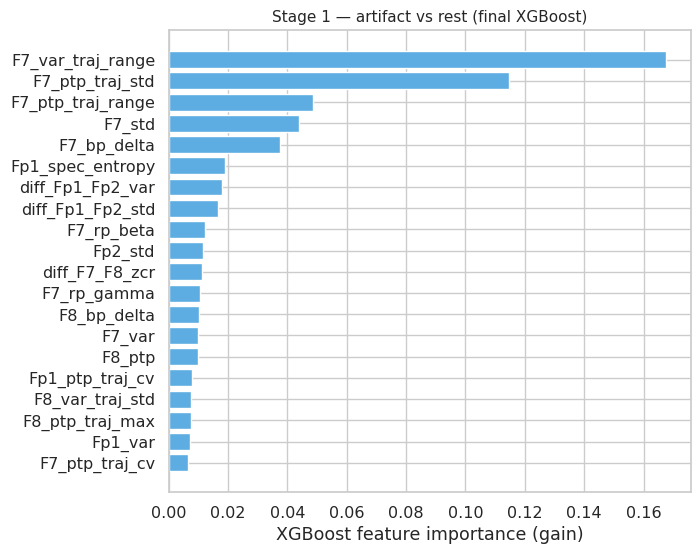

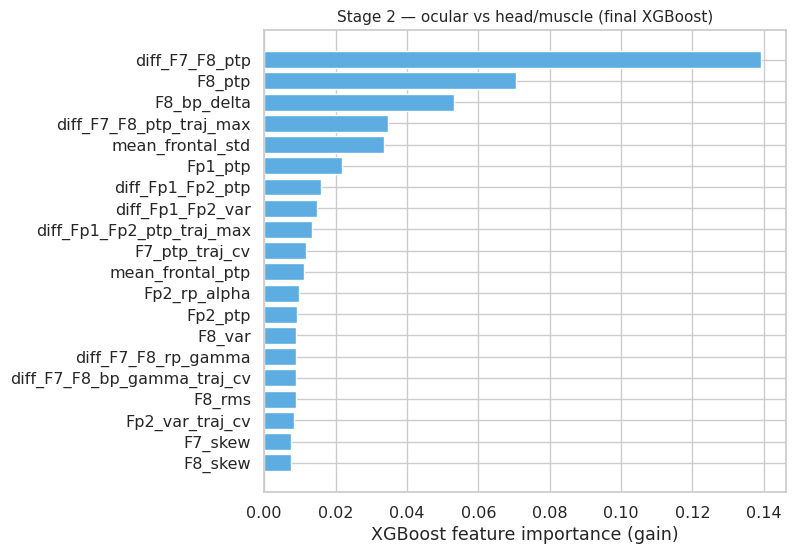

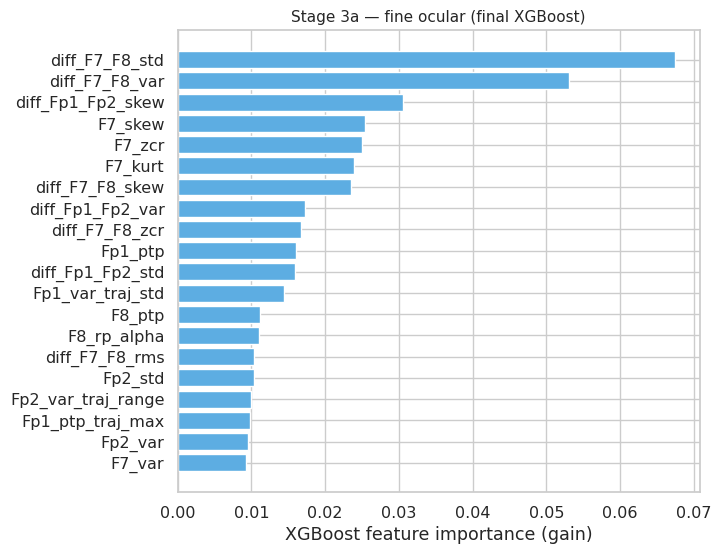

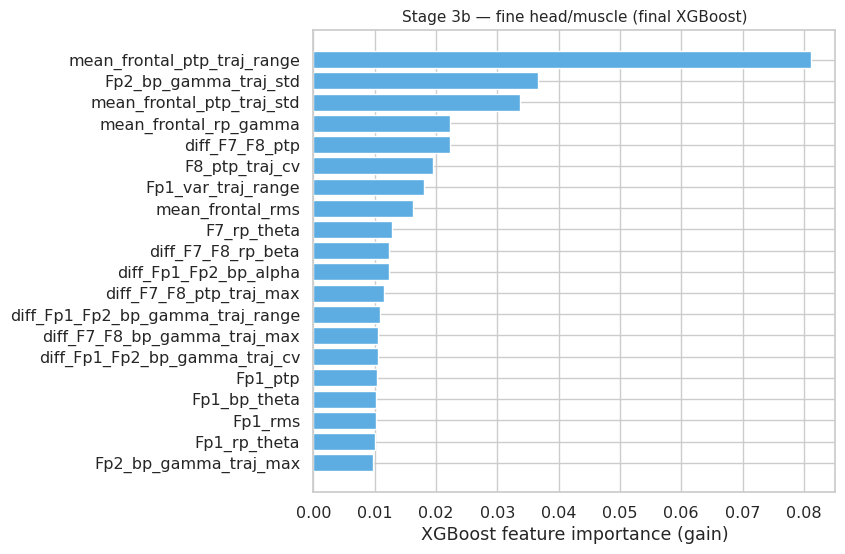

In [5]:
STAGE_TITLES = {
    "stage1": "Stage 1 — artifact vs rest",
    "stage2": "Stage 2 — ocular vs head/muscle",
    "stage3a": "Stage 3a — fine ocular",
    "stage3b": "Stage 3b — fine head/muscle",
}

if hier:
    for stage_key in ("stage1", "stage2", "stage3a", "stage3b"):
        clf = hier["classifiers"][stage_key]
        plot_stage_importance(
            stage_key, clf.feature_importances_,
            f"{STAGE_TITLES[stage_key]} (final XGBoost)",
        )
else:
    print("Plotting flat-7 global importance (hierarchical bundle unavailable).")
    plot_stage_importance(
        "flat7", xgb7.feature_importances_,
        "Flat 7-class XGBoost — global top features",
    )


## 5. SHAP — flat XGBoost (hold-out)

/tmp/ipykernel_33178/3522993777.py:22: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_global, X_ex, feature_names=feature_names, max_display=20, show=False)


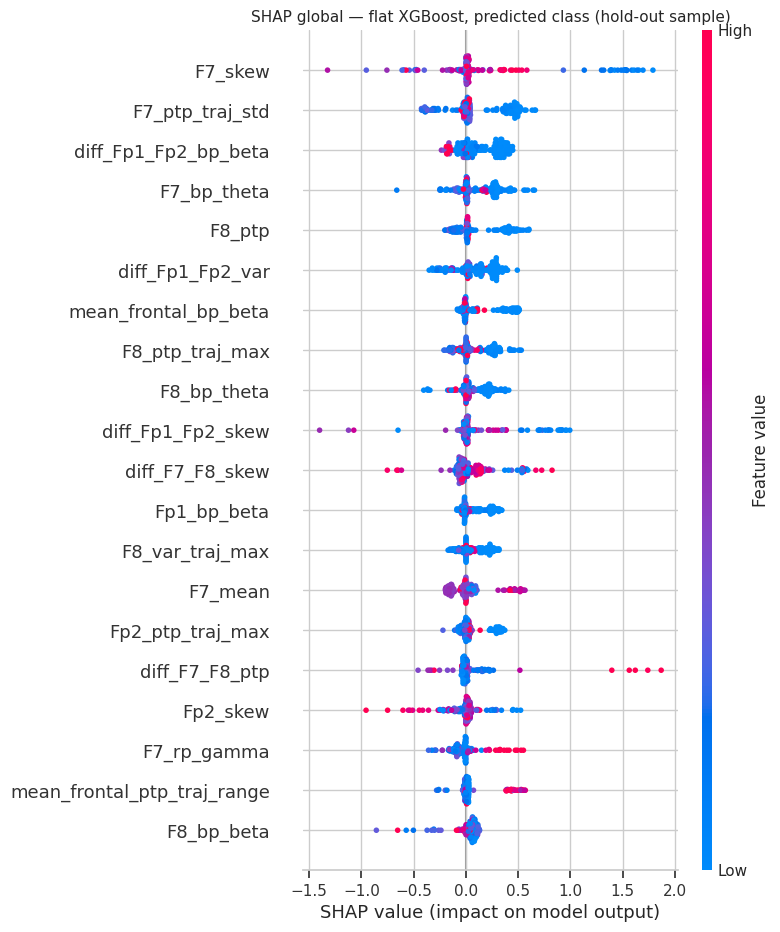

/tmp/ipykernel_33178/3522993777.py:33: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_by_class[cidx][m], X_ex[m], feature_names=feature_names, max_display=18, show=False)


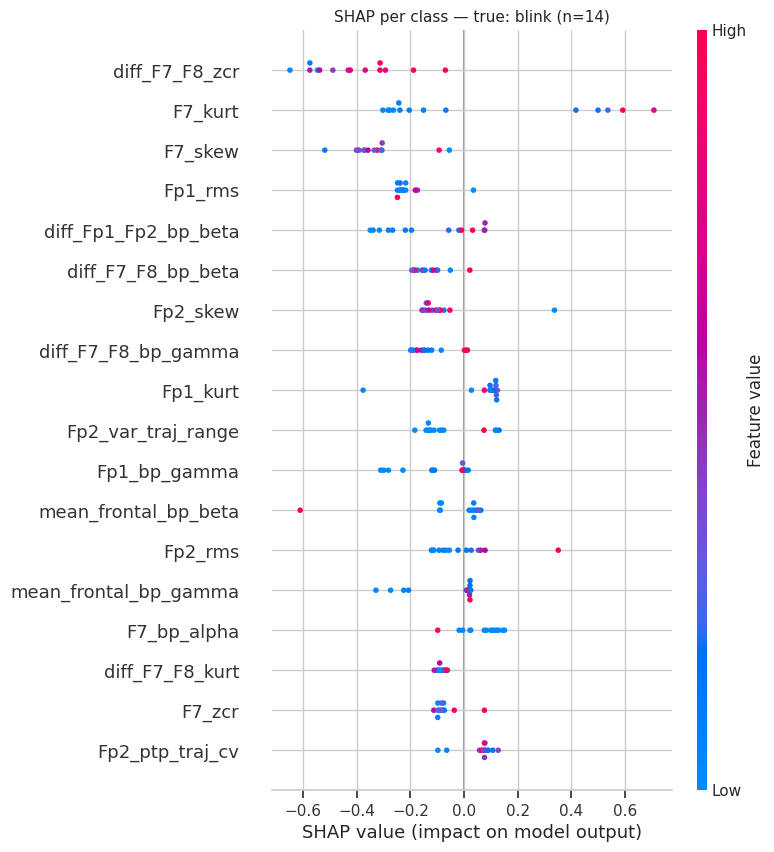

/tmp/ipykernel_33178/3522993777.py:33: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_by_class[cidx][m], X_ex[m], feature_names=feature_names, max_display=18, show=False)


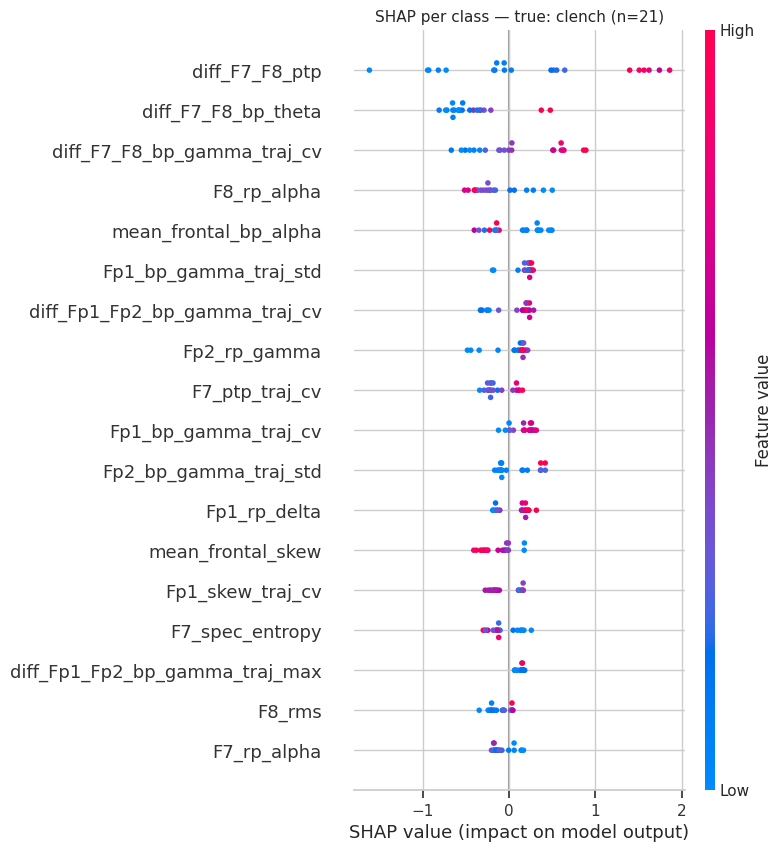

/tmp/ipykernel_33178/3522993777.py:33: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_by_class[cidx][m], X_ex[m], feature_names=feature_names, max_display=18, show=False)


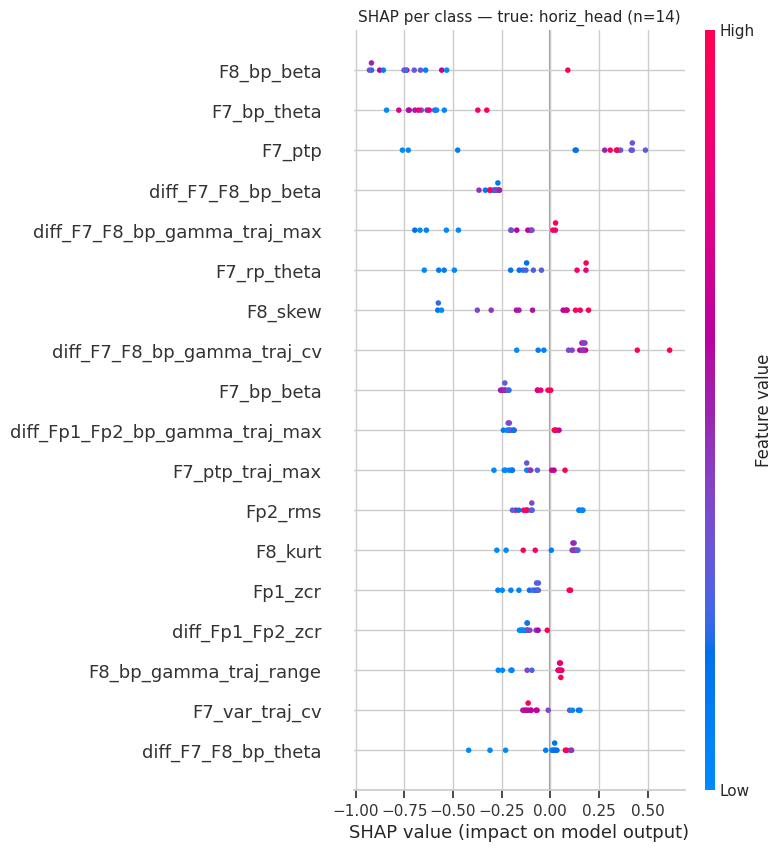

/tmp/ipykernel_33178/3522993777.py:33: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_by_class[cidx][m], X_ex[m], feature_names=feature_names, max_display=18, show=False)


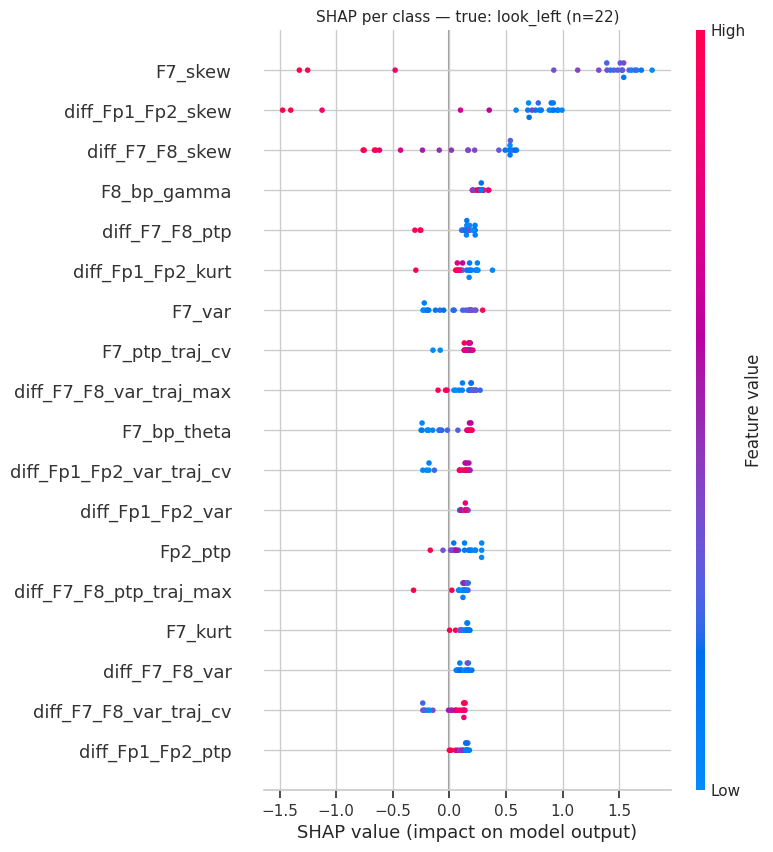

/tmp/ipykernel_33178/3522993777.py:33: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_by_class[cidx][m], X_ex[m], feature_names=feature_names, max_display=18, show=False)


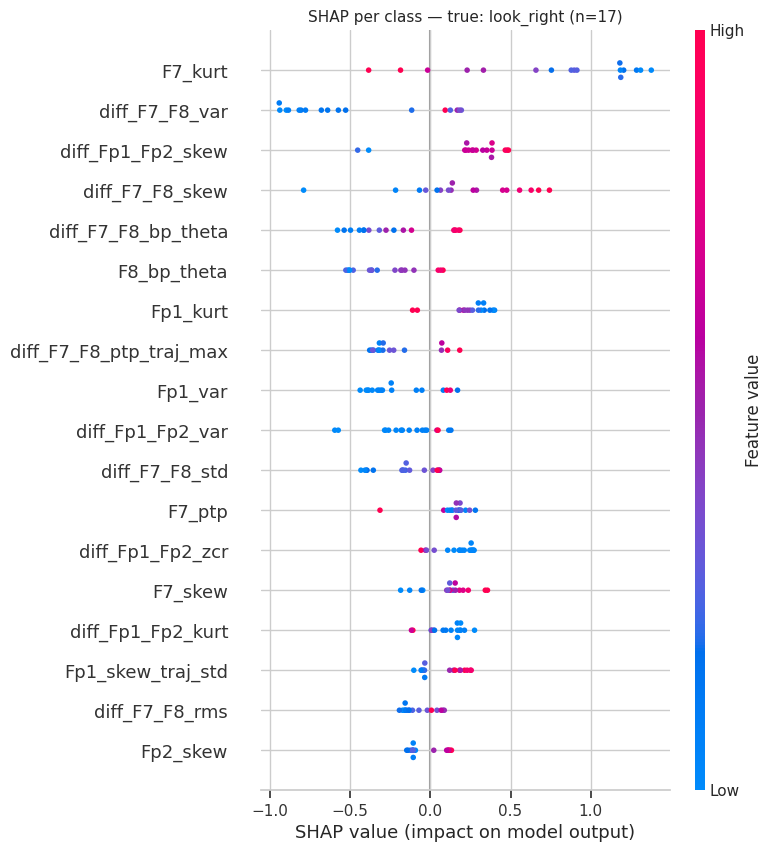

/tmp/ipykernel_33178/3522993777.py:33: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_by_class[cidx][m], X_ex[m], feature_names=feature_names, max_display=18, show=False)


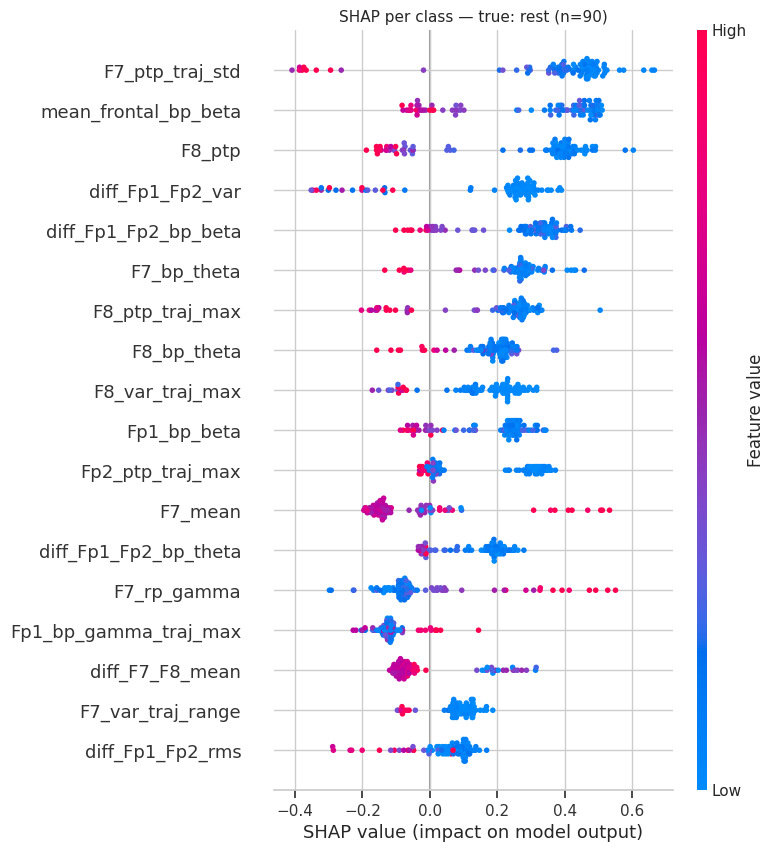

/tmp/ipykernel_33178/3522993777.py:33: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_by_class[cidx][m], X_ex[m], feature_names=feature_names, max_display=18, show=False)


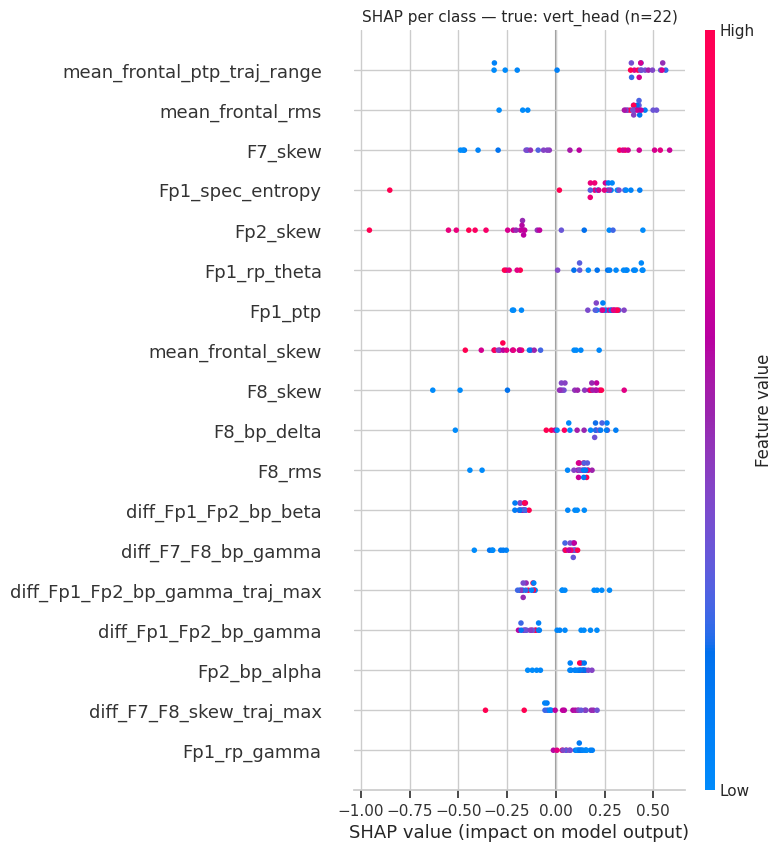

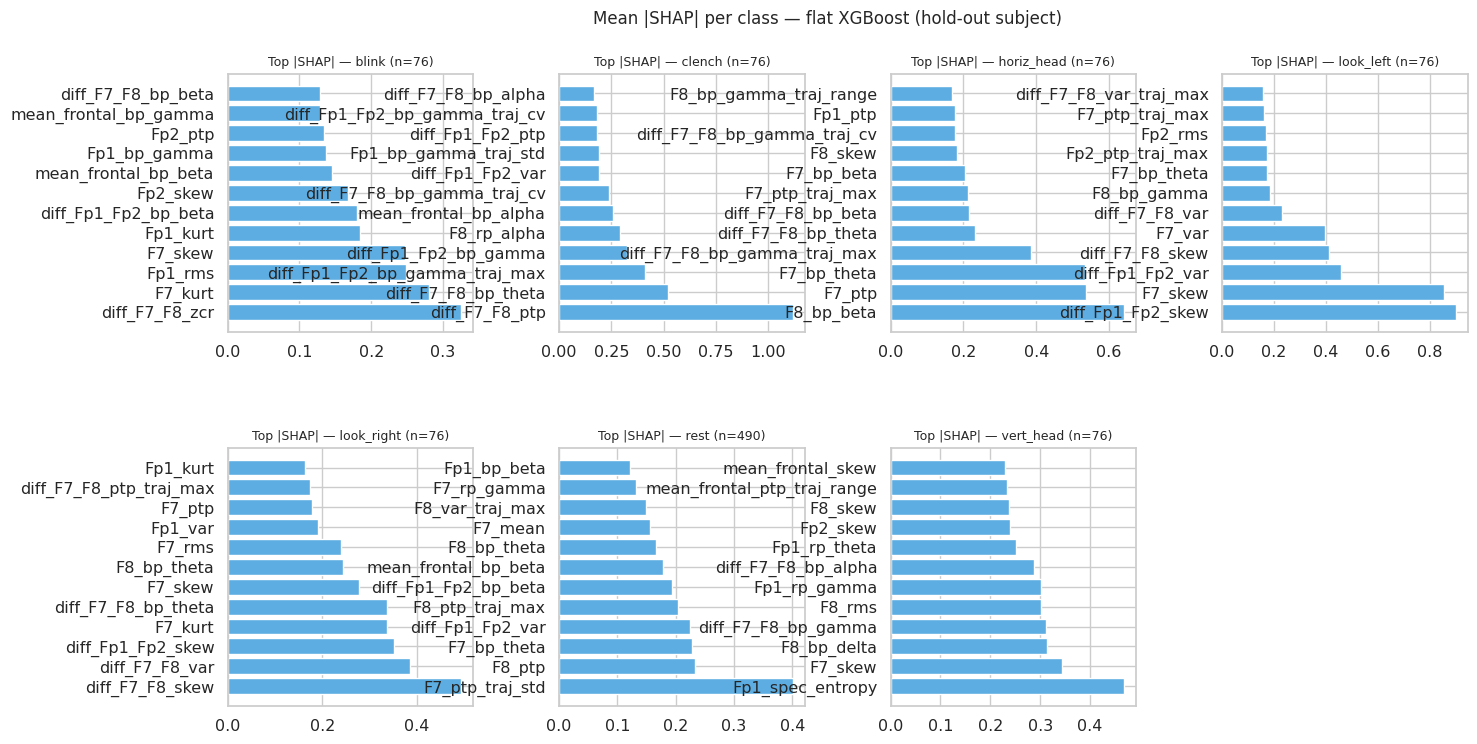

In [6]:
rng_shap = np.random.default_rng(SEED)
ex_idx = rng_shap.choice(te_idx, size=min(n_shap_ex, len(te_idx)), replace=False)
X_ex = X_feat[ex_idx]
y_ex = y_fine[ex_idx]
pred_ex = xgb7.predict(X_ex)

explainer = shap.TreeExplainer(xgb7)
sv = explainer.shap_values(X_ex)
if isinstance(sv, list):
    sv_by_class = [np.asarray(s, dtype=np.float64) for s in sv]
elif np.asarray(sv).ndim == 3:
    sv3 = np.asarray(sv, dtype=np.float64)
    sv_by_class = [sv3[:, :, k] for k in range(sv3.shape[2])]
else:
    sv_by_class = [np.asarray(sv, dtype=np.float64)]

sv_global = np.zeros_like(sv_by_class[0])
for i, p in enumerate(pred_ex):
    sv_global[i] = sv_by_class[int(p)][i]

plt.figure(figsize=(11, 6))
shap.summary_plot(sv_global, X_ex, feature_names=feature_names, max_display=20, show=False)
plt.title("SHAP global — flat XGBoost, predicted class (hold-out sample)", fontsize=11)
plt.tight_layout(); plt.show()

for cidx, cls in enumerate(le_xgb.classes_):
    m = y_ex == cls
    n_cls = int(m.sum())
    if n_cls < 5:
        print(f"Skip beeswarm '{cls}': n={n_cls}")
        continue
    plt.figure(figsize=(10, 5.5))
    shap.summary_plot(sv_by_class[cidx][m], X_ex[m], feature_names=feature_names, max_display=18, show=False)
    plt.title(f"SHAP per class — true: {cls} (n={n_cls})", fontsize=11)
    plt.tight_layout(); plt.show()

sv_hold = explainer.shap_values(X_feat[te_idx])
if isinstance(sv_hold, list):
    sv_hold_list = [np.asarray(s, dtype=np.float64) for s in sv_hold]
else:
    sv3h = np.asarray(sv_hold, dtype=np.float64)
    sv_hold_list = [sv3h[:, :, k] for k in range(sv3h.shape[2])]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.subplots_adjust(top=0.90, hspace=0.45, wspace=0.35)
for cidx, cls in enumerate(le_xgb.classes_):
    m = y_fine[te_idx] == cls
    ax = axes.ravel()[cidx]
    if m.sum() < 3:
        ax.axis("off"); ax.set_title(f"{cls} (no data)"); continue
    mean_abs = np.abs(sv_hold_list[cidx]).mean(0).ravel()
    top = np.argsort(mean_abs)[-12:]
    ax.barh([feature_names[i] for i in top], mean_abs[top], color="#5dade2")
    ax.invert_yaxis()
    ax.set_title(f"Top |SHAP| — {cls} (n={m.sum()})", fontsize=9)
axes.ravel()[7].axis("off")
fig.suptitle("Mean |SHAP| per class — flat XGBoost (hold-out subject)", fontsize=12)
plt.show()


## 6. EEGNet (05 LOSO) — Grad-CAM per artefact class

Each fine label is explained on the **stage model** that predicts it (stage1 → `rest`, stage3a → ocular, stage3b → head/muscle).

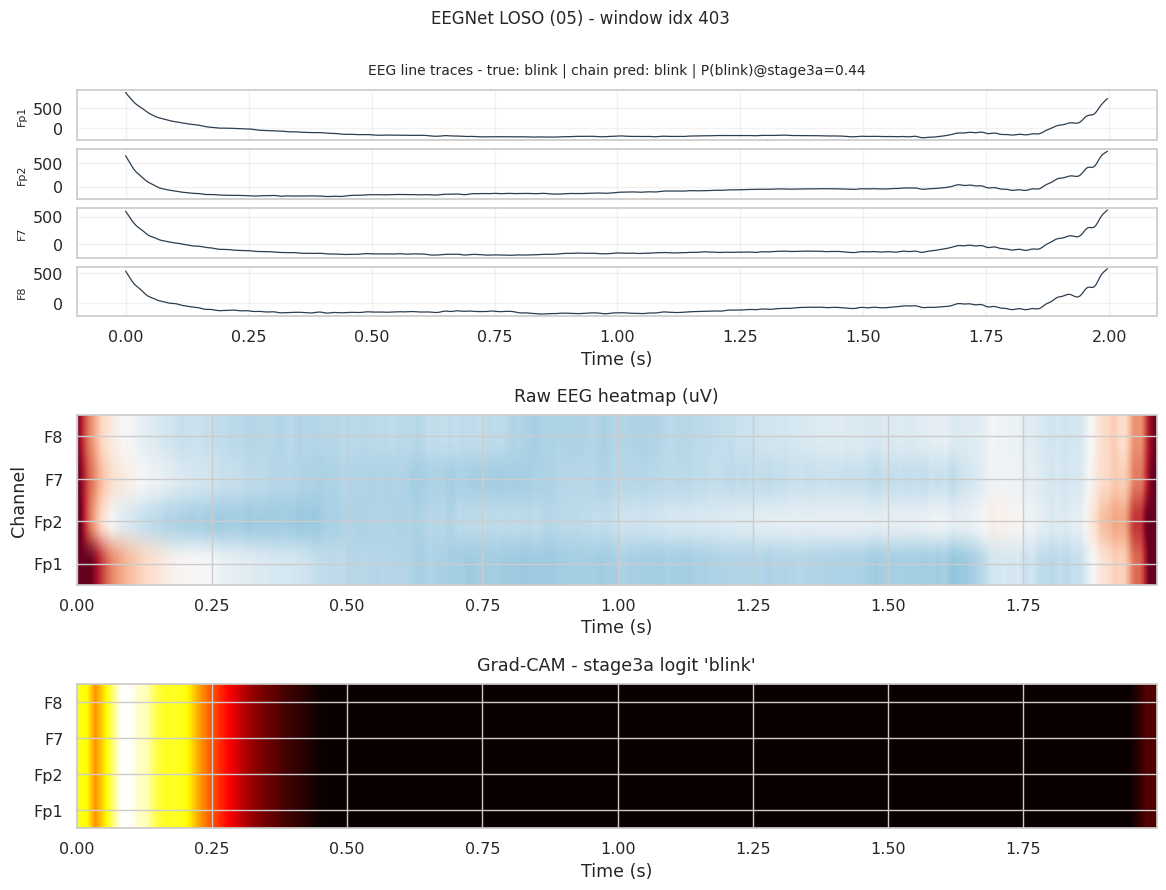

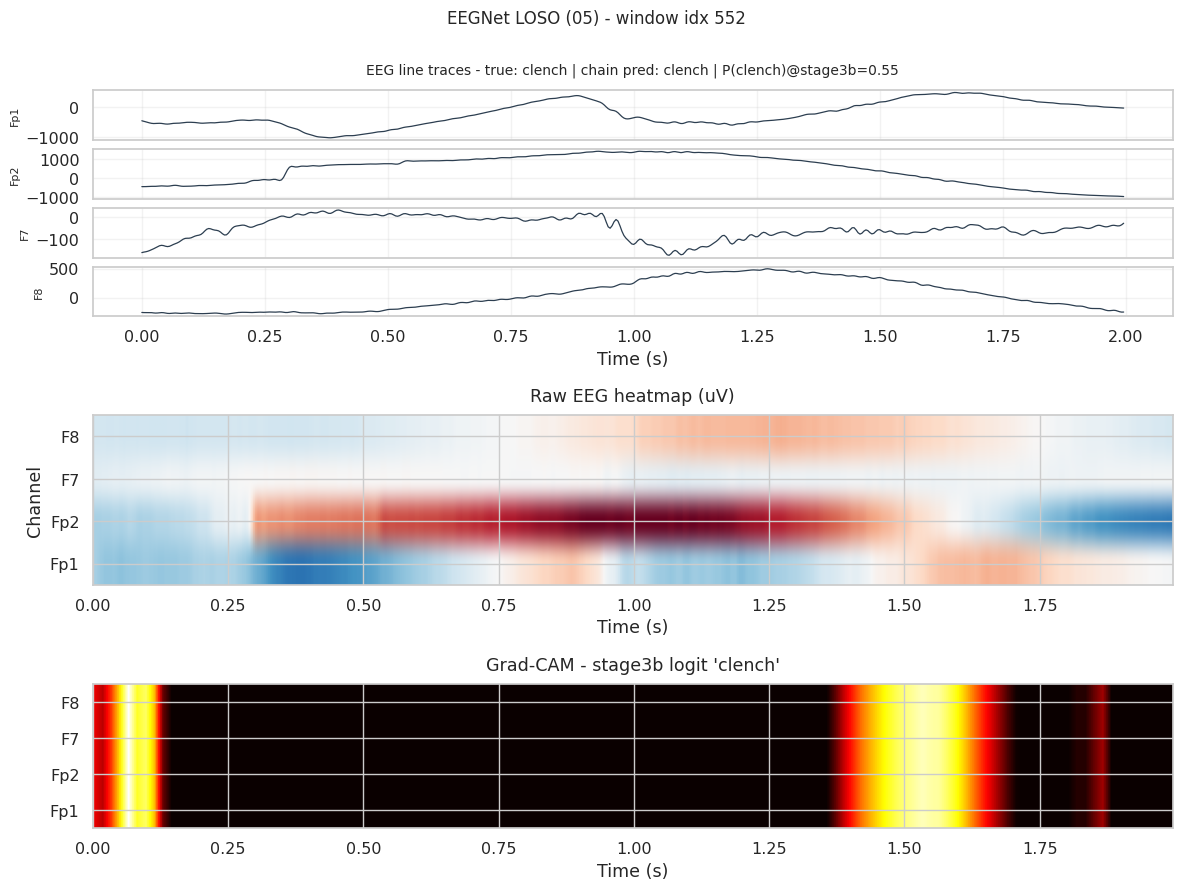

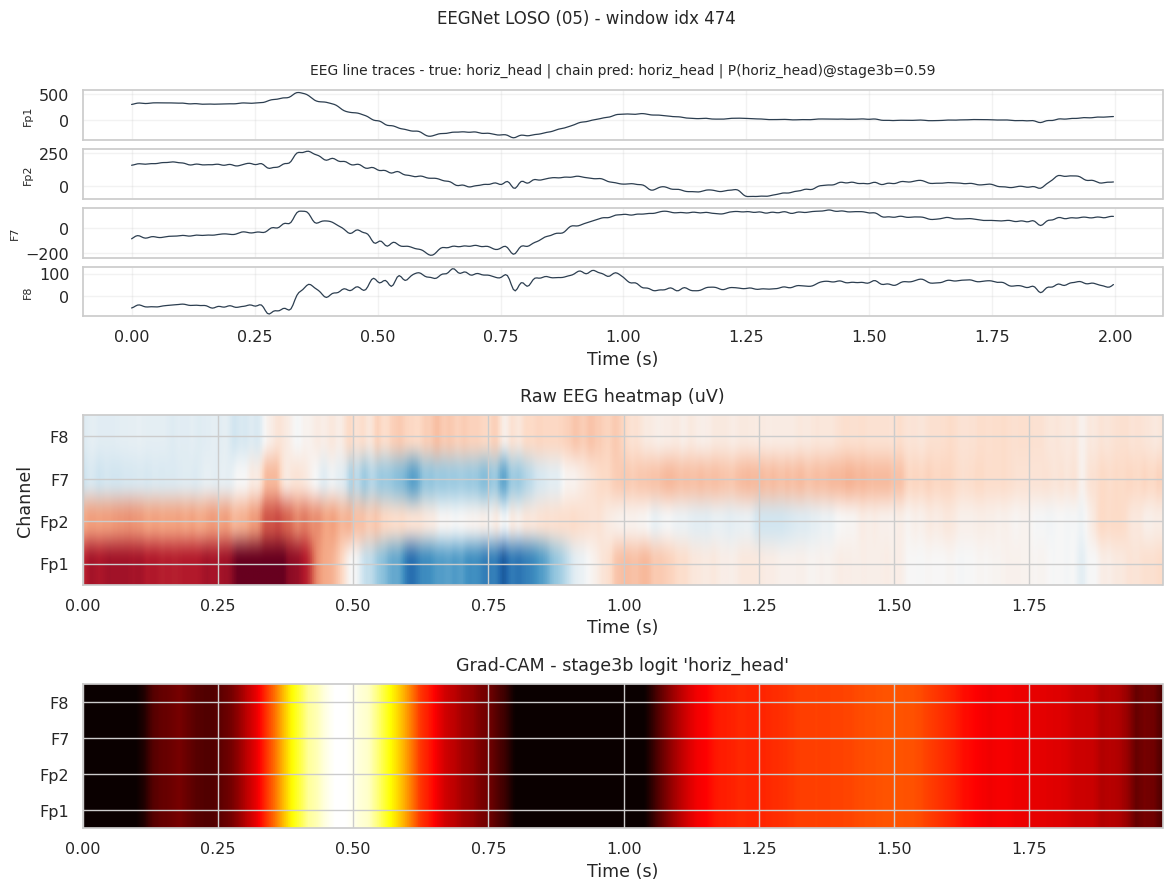

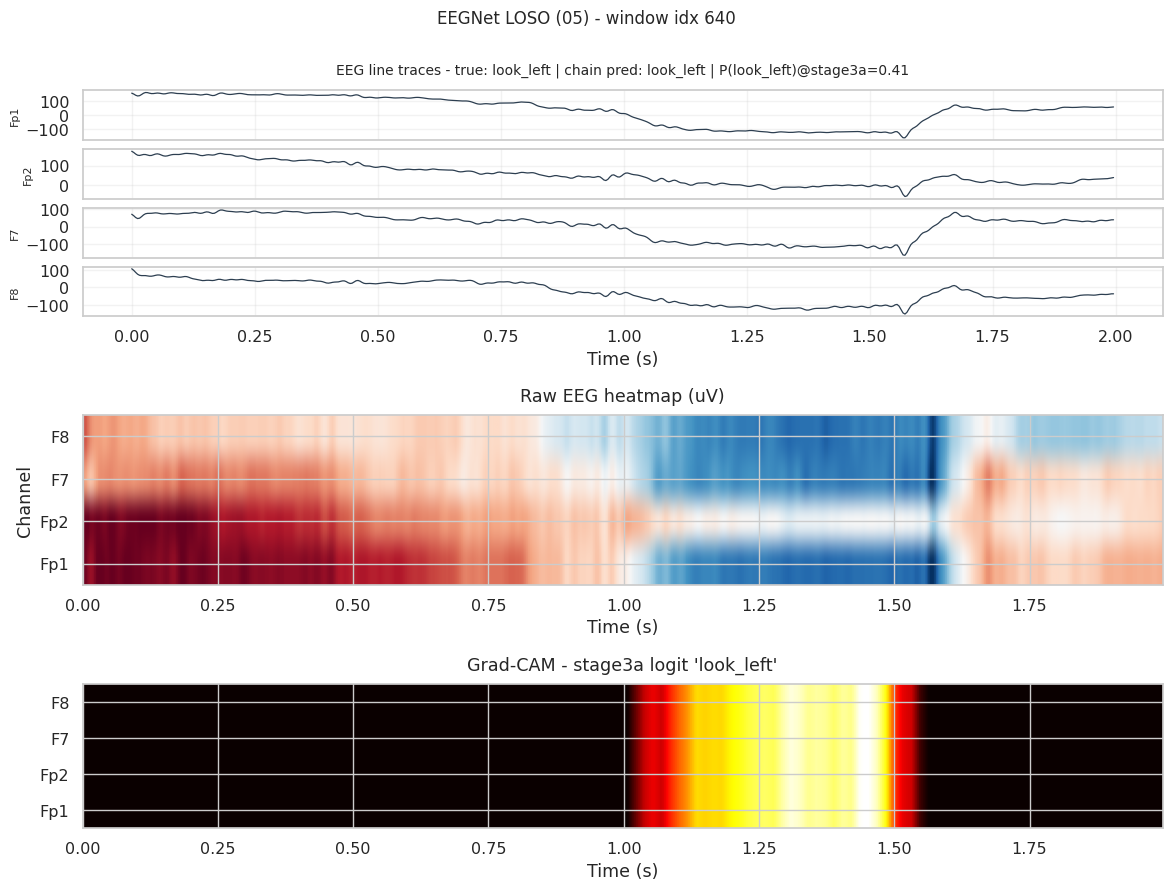

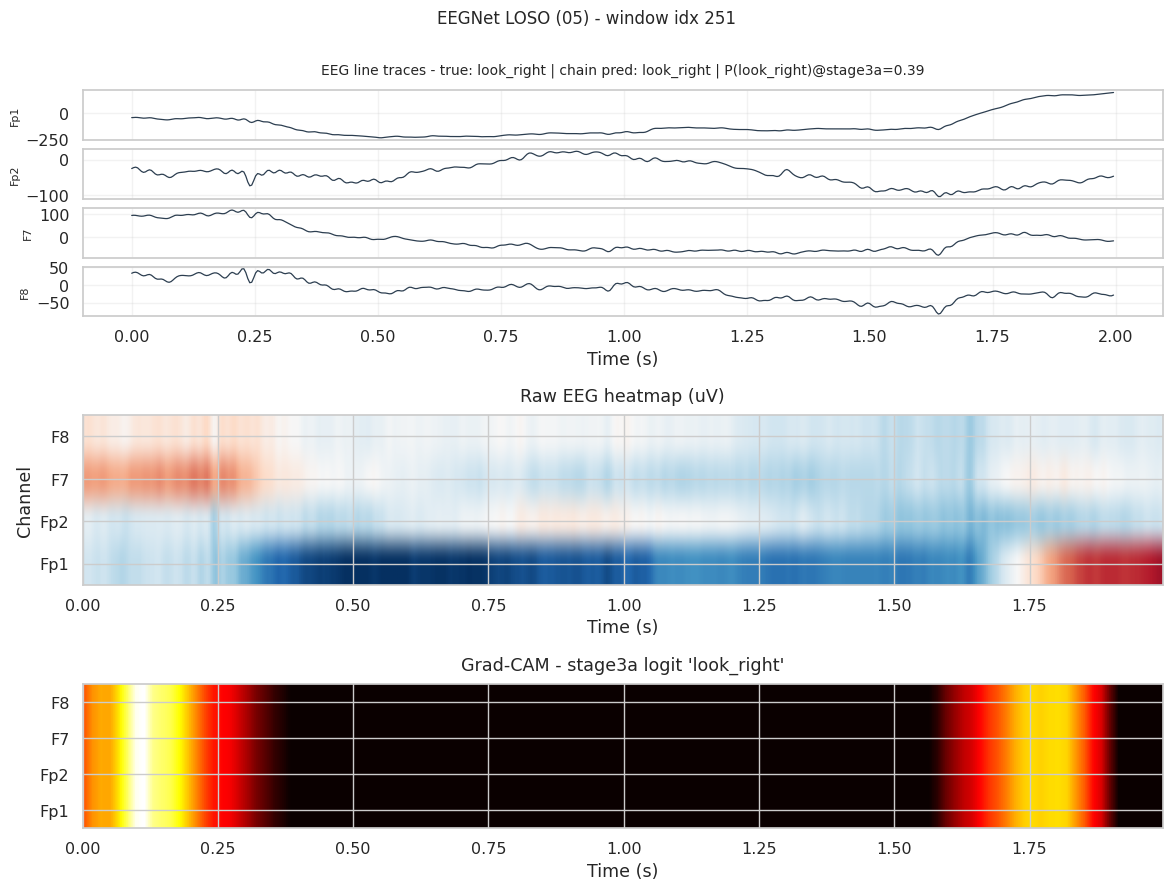

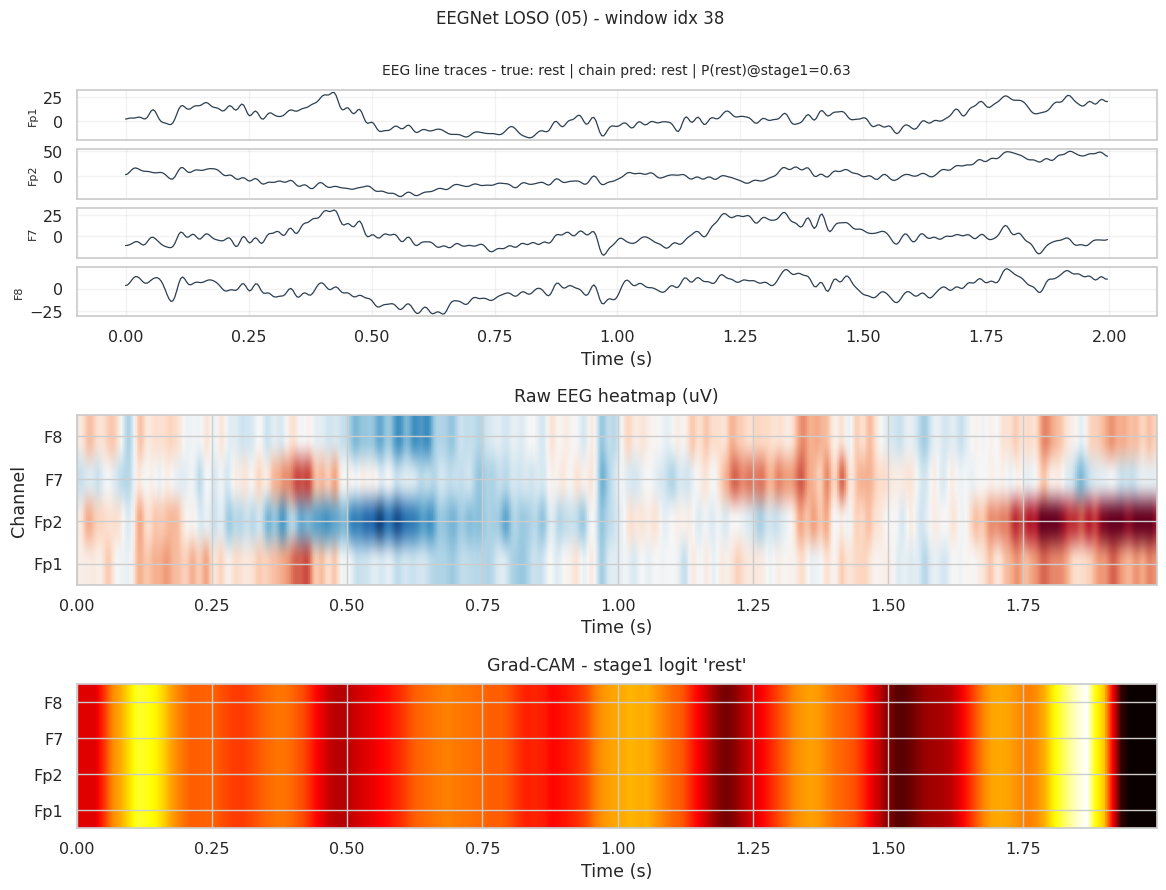

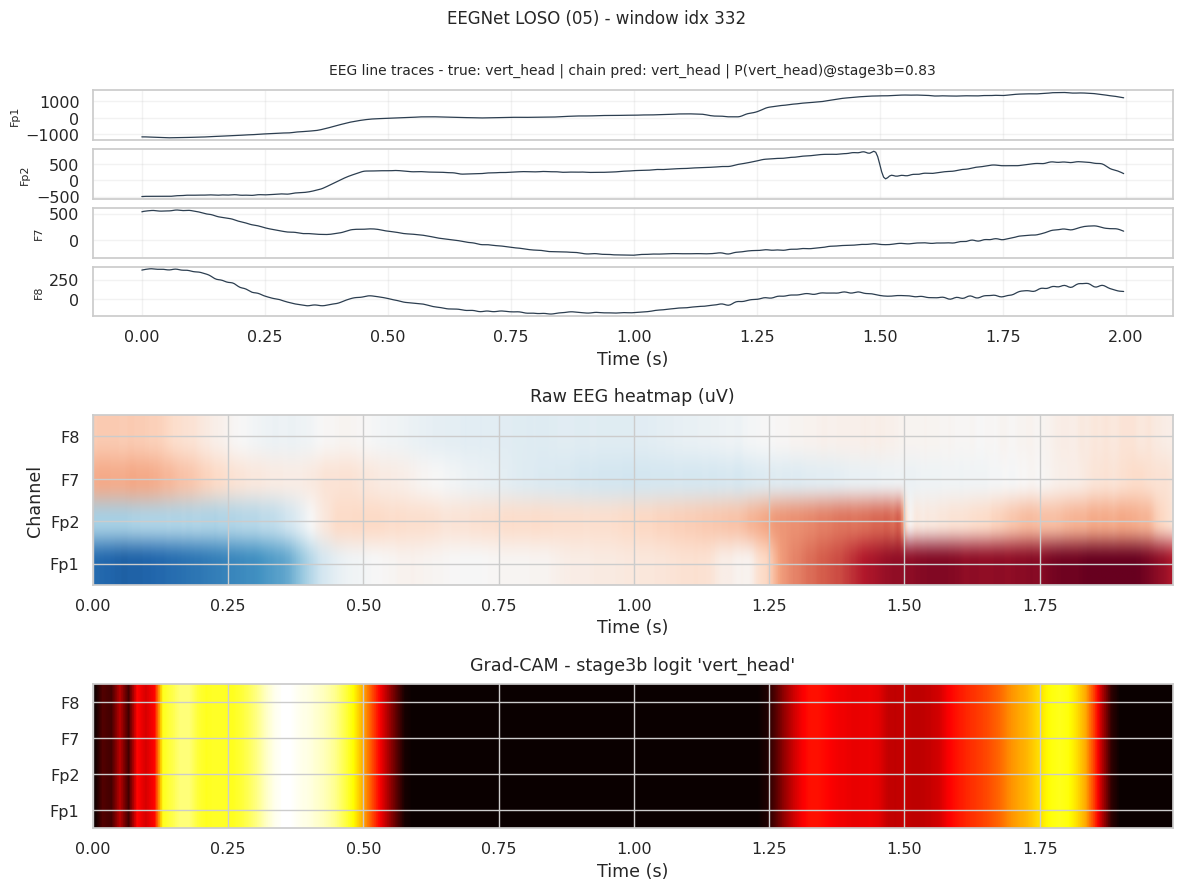

In [7]:
for lbl in FINE_CLASSES:
    picks = pick_idx(y_fine[te_idx], pred_e, lbl, 1)
    if not picks:
        print(f"Skip EEGNet '{lbl}': no hold-out example")
        continue
    gi = int(te_idx[picks[0]])
    plot_eegnet_hier_class_panel(gi, lbl, eeg_models, eeg_loso_meta, pred_e_all)
